Hücre 1: Kütüphaneler

In [2]:

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time


from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, Birch
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.model_selection import train_test_split

warnings.filterwarnings('ignore')
%matplotlib inline
pd.set_option('display.float_format', lambda x: '%.2f' % x)

Hücre 2: Veri Yükleme ve Ön İşleme

In [3]:


#Veri Yükleme
df = pd.read_csv('customer_segmentation.csv')


# Doğum yılından yaş hesaplama (veride firmaya en son kayıt olan kişinin kayıt tarihi 2014 yıllı)
df['Age'] = 2014 - df['Year_Birth']

# Toplam Harcama
df['Total_Spending'] = df['MntWines'] + df['MntFruits'] + df['MntMeatProducts'] + \
                       df['MntFishProducts'] + df['MntSweetProducts'] + df['MntGoldProds']

# Çocuk Sayısı
df['Children'] = df['Kidhome'] + df['Teenhome']

# Medeni Hal (Sadeleştirme)
df['Living_Status'] = df['Marital_Status'].replace({
    'Married': 'Partner', 'Together': 'Partner',
    'Single': 'Alone', 'Divorced': 'Alone', 'Widow': 'Alone', 
    'Absurd': 'Alone', 'YOLO': 'Alone'
})

# Eğitim (Sıralı Hale Getirme: Sayıya çeviriyoruz)
education_map = {'Basic': 0, '2n Cycle': 1, 'Graduation': 1, 'Master': 2, 'PhD': 3}
df['Education_Level'] = df['Education'].map(education_map)

# Gereksiz Sütunları Atma
cols_to_drop = ['ID', 'Year_Birth', 'Dt_Customer', 'Z_CostContact', 'Z_Revenue', 
                'Marital_Status', 'Education', 'Kidhome', 'Teenhome']
X = df.drop(columns=cols_to_drop, errors='ignore')

# encoding
# Kategorik olan 'Living_Status' sütununu sayıya çeviriyoruz (One-Hot).Böylece veri setinin tamamı sayısal oluyor.

X = pd.get_dummies(X, columns=['Living_Status'], drop_first=True)

# Eksik Veri Tespiti ve Doldurma 
print(f"Eksik Veri Sayısı: {X.isnull().sum().sum()}")
imp = SimpleImputer(strategy='median')
X = pd.DataFrame(imp.fit_transform(X), columns=X.columns)

# Outlier Temizliği
age_limit = X['Age'].quantile(0.99)        # Yaşın %99. dilimi
income_limit = X['Income'].quantile(0.99)  # Gelirin %99. dilimi

print(f"Otomatik Hesaplanan Sınırlar -> Yaş Sınırı: {age_limit:.1f}, Gelir Sınırı: {income_limit:.1f}")

# Bu sınırlardan büyük olanları atalım
X = X[(X['Age'] < age_limit) & (X['Income'] < income_limit)]

# Standardizasyon
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

# Train-Test Split
X_train, X_test = train_test_split(X_scaled, test_size=0.1, random_state=42)

print(f"\nVeri Hazırlandı.")
print(f"Toplam Veri: {X_scaled.shape}")
print(f"Train Seti: {X_train.shape}")

Eksik Veri Sayısı: 24
Otomatik Hesaplanan Sınırlar -> Yaş Sınırı: 69.0, Gelir Sınırı: 94437.7

Veri Hazırlandı.
Toplam Veri: (2191, 25)
Train Seti: (1971, 25)


Hücre 3: Küme Sayısını Belirleme (Elbow ve Silhouette)

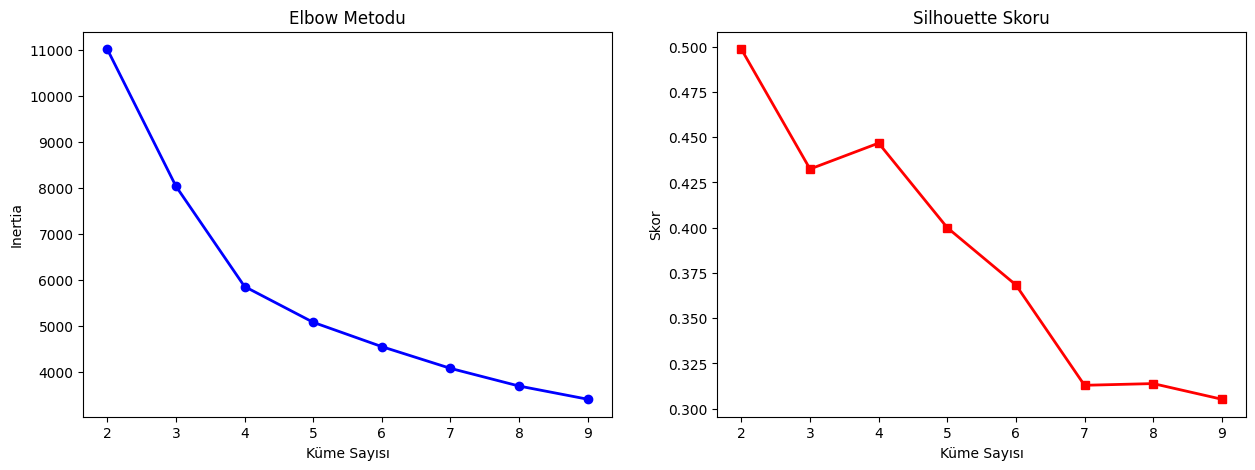


>>> TAVSİYE EDİLEN KÜME SAYISI: 2


In [4]:


# Veriyi görselleştirmek ve gürültüyü atmak için PCA (3 Boyut)
pca = PCA(n_components=3)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

inertia = []
sil_scores = []
k_range = range(2, 10)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_train_pca)
    inertia.append(km.inertia_)
    sil_scores.append(silhouette_score(X_train_pca, km.labels_))

# Grafikler
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

# Elbow
ax[0].plot(k_range, inertia, 'bo-', lw=2)
ax[0].set_title('Elbow Metodu')
ax[0].set_xlabel('Küme Sayısı')
ax[0].set_ylabel('Inertia')

# Silhouette
ax[1].plot(k_range, sil_scores, 'rs-', lw=2)
ax[1].set_title('Silhouette Skoru')
ax[1].set_xlabel('Küme Sayısı')
ax[1].set_ylabel('Skor')

plt.show()

# En yüksek Silhouette skoruna sahip K değerini seçelim
OPTIMAL_K = k_range[np.argmax(sil_scores)]
print(f"\n>>> TAVSİYE EDİLEN KÜME SAYISI: {OPTIMAL_K}")

Hücre 4: Değerlendirme Fonksiyonu

In [5]:
# --- tekrar tekrar kullanmak için bir fonksiyon yazalım ---
def evaluate_clustering(model_name, labels, X_pca_data, time_taken):
    # Skorlar
    sil = silhouette_score(X_pca_data, labels)
    db = davies_bouldin_score(X_pca_data, labels)
    
    print(f"\n{'='*60}\nMODEL: {model_name}\n{'='*60}")
    print(f"Süre: {time_taken:.4f} sn")
    print(f"Silhouette Score: {sil:.4f}")
    print(f"Davies-Bouldin:   {db:.4f}")
    
    # Görselleştirme
    plt.figure(figsize=(8, 5))
    sns.scatterplot(x=X_pca_data[:,0], y=X_pca_data[:,1], hue=labels, palette='viridis', s=60, alpha=0.8)
    plt.title(f'{model_name} - Küme Dağılımı')
    plt.xlabel('Gelir ve Harcama Ekseni (PCA 1)')
    plt.ylabel('Yaş ve Aile Ekseni (PCA 2)')
    plt.legend(title='Küme')
    plt.show()
    
    return {'Model': model_name, 'Silhouette': sil, 'DB Index': db}

Hücre 5: 3 Farklı Model Eğitimi

>>> 1. K-Means...

MODEL: K-Means
Süre: 0.0155 sn
Silhouette Score: 0.4986
Davies-Bouldin:   0.8528


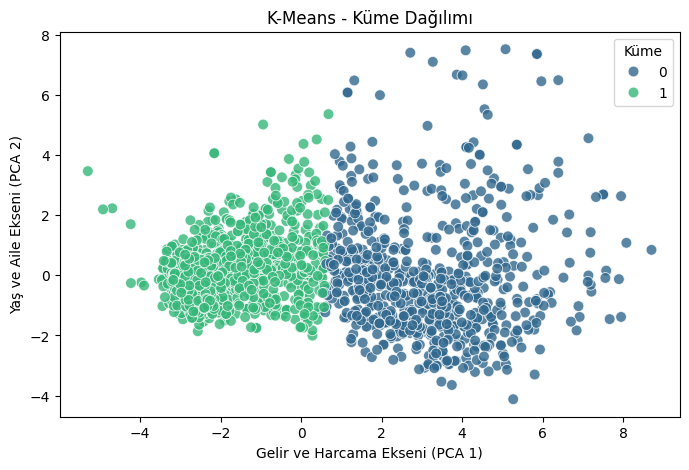


>>> 2. Agglomerative...

MODEL: Agglomerative
Süre: 0.0631 sn
Silhouette Score: 0.4707
Davies-Bouldin:   0.9092


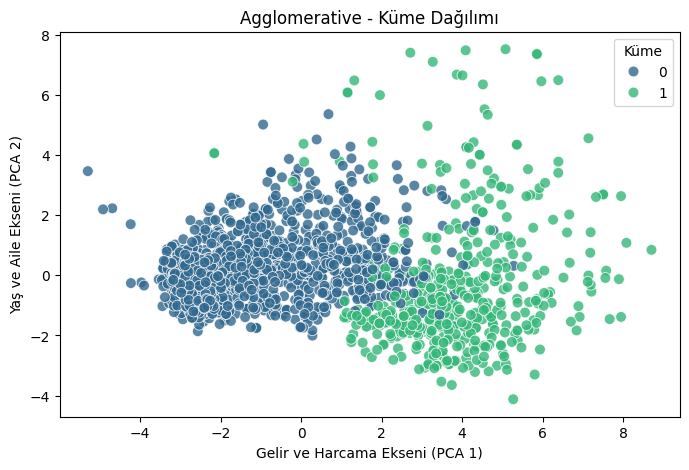


>>> 3. BIRCH...

MODEL: BIRCH
Süre: 0.0405 sn
Silhouette Score: 0.4647
Davies-Bouldin:   0.8762


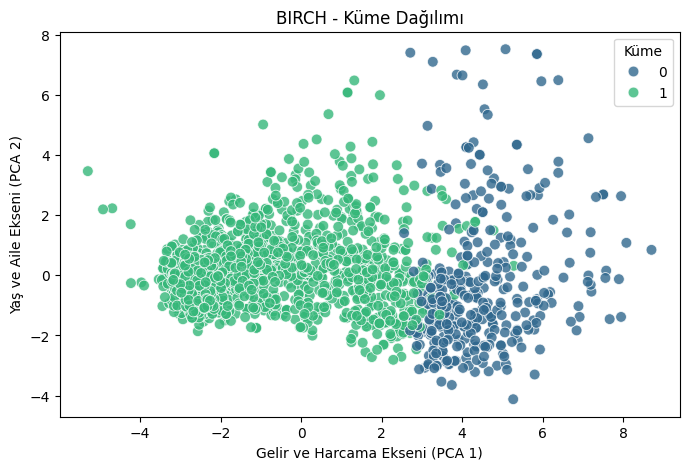

In [6]:

results = []

# 1. K-Means
print(">>> 1. K-Means...")
start = time.time()
km = KMeans(n_clusters=OPTIMAL_K, random_state=42, n_init=10)
labels_km = km.fit_predict(X_train_pca)
results.append(evaluate_clustering("K-Means", labels_km, X_train_pca, time.time()-start))

# 2. Agglomerative Clustering
print("\n>>> 2. Agglomerative...")
start = time.time()
agg = AgglomerativeClustering(n_clusters=OPTIMAL_K)
labels_agg = agg.fit_predict(X_train_pca)
results.append(evaluate_clustering("Agglomerative", labels_agg, X_train_pca, time.time()-start))

# 3. BIRCH
print("\n>>> 3. BIRCH...")
start = time.time()
br = Birch(n_clusters=OPTIMAL_K, threshold=0.5, branching_factor=50)
labels_br = br.fit_predict(X_train_pca)
results.append(evaluate_clustering("BIRCH", labels_br, X_train_pca, time.time()-start))

Hücre 6: Karşılaştırma Tablosu ve Grafiği


=== PERFORMANS TABLOSU ===
           Model  Silhouette  DB Index
0        K-Means        0.50      0.85
1  Agglomerative        0.47      0.91
2          BIRCH        0.46      0.88


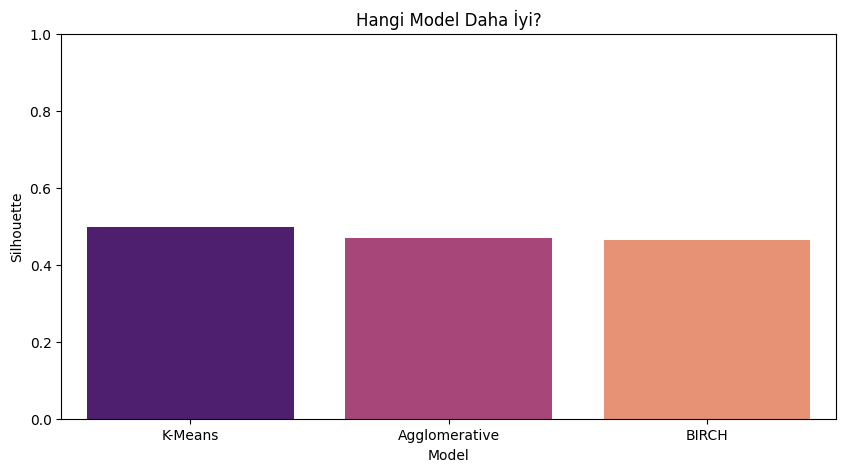

In [7]:

df_res = pd.DataFrame(results).sort_values(by='Silhouette', ascending=False)
print("\n=== PERFORMANS TABLOSU ===")
print(df_res)

plt.figure(figsize=(10, 5))
sns.barplot(x='Model', y='Silhouette', data=df_res, palette='magma')
plt.title('Hangi Model Daha İyi?')
plt.ylim(0, 1)
plt.show()

Hücre 7: Yorumlama 


=== MÜŞTERİ SEGMENT PROFİLLERİ ===
          Income  Total_Spending   Age  Children
Cluster                                         
0       51829.04          602.54 45.62      0.95
1       51889.78          600.95 44.91      0.97


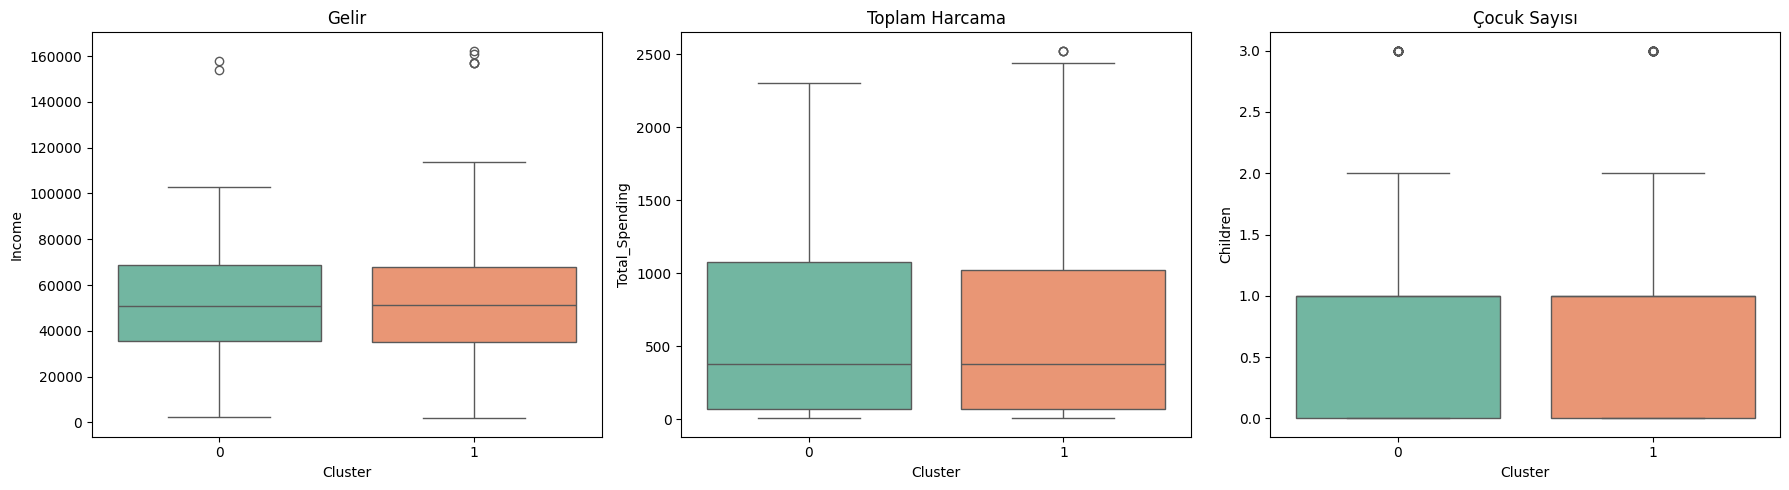

In [8]:

# Orijinal veriye etiketleri ekleyelim
# X_train scaled olduğu için orijinal verinin indekslerini kullanıp ham veriyi alalım
train_indices = X_train.index
df_analysis = df.loc[train_indices].copy()
df_analysis['Cluster'] = labels_km # K-Means etiketleri

# Profil Özeti
summary = df_analysis.groupby('Cluster')[['Income', 'Total_Spending', 'Age', 'Children']].mean()
print("\n=== MÜŞTERİ SEGMENT PROFİLLERİ ===")
print(summary)

# Kutu Grafikleri (Boxplot)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(x='Cluster', y='Income', data=df_analysis, ax=axes[0], palette='Set2'); axes[0].set_title('Gelir')
sns.boxplot(x='Cluster', y='Total_Spending', data=df_analysis, ax=axes[1], palette='Set2'); axes[1].set_title('Toplam Harcama')
sns.boxplot(x='Cluster', y='Children', data=df_analysis, ax=axes[2], palette='Set2'); axes[2].set_title('Çocuk Sayısı')
plt.tight_layout()
plt.show()
